# Course: Introduction to Artificial Intelligence and Data Science 

This exercise is designed to use a simple dataset to introduce and illustrate some of the fundamental methods and skills involved in classical machine learning and neural network learning. 

## About the Jupyter Notebook

This Jupyter Notebook consists of individual cells that can be executed one after the other. Cells containing executable code contain Python code, whilst text cells (markdown) are used for documentation and descriptions.

This allows **executable code**, **documentation and descriptions** can be clearly separated from one another, whilst still linking code with explanatory text and structuring the flow of the exercise in a way that is easy to follow.

A selected cell or all cells can, for example, be executed via the Jupyter Notebook menu. In doing so, cells containing **executable programme instructions** are run. Cells should generally be executed in the order in which they appear, as later cells may access variables and results from previous cells.

Modified programme cells can be re-run at any time. When this happens, the instructions in the respective cell are executed again and any existing variables or results are overwritten if necessary. This allows you to test changes to the programme instructions directly and check their effects.

As subsequent programme cells may rely on the modified variables or results, all subsequent cells that depend on them must also be re-run. This ensures that the results displayed are based on the current state of the programme instructions.

## Task: Identifying the iris species (Iris) based on measurement data

The **Iris dataset** is to be used for the classification task. It contains measurements of various irises (Iris). 

Documentation: https://archive.ics.uci.edu/dataset/53/iris

Four features were recorded for each flower:

* Sepal length
* Sepal width
* Petal length
* Petal width

In addition, the corresponding genus is specified for each flower as the **target class**. The dataset comprises three genera:

* **Iris setosa**
* **Iris versicolour**
* **Iris virginica**

Our task is to **classify** the genus of an iris flower based on the four measured features.

Using the measurement data, we will train both a model from the portfolio of various classical machine learning approaches and a simple neural network, each of which can automatically recognise the genus when the corresponding lengths and widths of the petals and sepals are given.
Classification is therefore not based on image information but on measurable characteristics of the petals.

To illustrate a classical machine learning method, K-nearest neighbour classification is used. 

Documentation: https://de.wikipedia.org/wiki/N%C3%A4chste-Nachbarn-Klassifikation

To illustrate a method based on neural networks, a simple multi-layer feedforward neural network (multi-layer perceptron) is used. 

Documentation: https://de.wikipedia.org/wiki/Multi-Layer-Perzeptron

To solve the exercise, it is divided into 3 parts:
* **Part A**: importing libraries and preparing the data
* **Part B**: classification using the K-nearest-neighbour algorithm
* **Part C**: classification using a simple multi-layer neural network (multi-layer perceptron) 

### Understanding the dataset

The starting point for any machine learning task is, first and foremost, an understanding of the underlying data. Before a model can be trained, it is necessary to know which features and target classes the dataset contains and how they are structured. The following diagram illustrates the different genera and species of Iris and their petals, and shows which measurable characteristics are used for classification.

![Iris](https://www.embedded-robotics.com/wp-content/uploads/2022/01/Iris-Dataset-Classification-1024x367.png)


# Part A
The aim of Part A is to import the libraries (modules, classes and functions) required for the subsequent programme blocks, to present the dataset used, and to prepare it for the two classification methods to be compared.

### **Task 0: Managing Imports**
Python already provides basic functionality; however, to complete this exercise, additional **libraries with their modules, classes and functions** are required. To this end, the following code cell must be expanded to include the necessary **imports** as the programme is developed. 

In [27]:
# Task 0
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.preprocessing import StandardScaler

keras.utils.set_random_seed(42)

## 

### **Providing a dataset**

First of all, you will need the dataset to be used for subsequent processing. For this exercise, the **Iris dataset** is used. This is already part of the **Scikit-Learn** library and can therefore be loaded directly.

**Scikit-Learn** is an open-source library for machine learning in Python. It provides numerous pre-implemented algorithms, as well as classes, methods and functions for the development and application of machine learning models. In addition, **Scikit-Learn** offers various datasets, including the **Iris dataset**.

Documentation on the dataset: https://scikit-learn.org/stable/datasets/toy_dataset.html#iris-plants-dataset

### **Task 1 – Importing Scikit-Learn**

First of all, in the first code cell created above, you need to import the function for loading the Iris dataset from the **datasets** module.

Documentation on the dataset: https://scikit-learn.org/stable/datasets/toy_dataset.html#iris-plants-dataset

### **Task 2 – Load and examine the dataset**

Load the Iris dataset below and store it in a variable named **iris**.

The dataset is returned as an object with various attributes. Then output the **names of the features** and the **names of the target classes**.

Documentation: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html#sklearn.datasets.load_iris

In [28]:
# Task 2
iris = load_iris()
print("Features:", iris.feature_names)
print("Classes:", iris.target_names)

Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: ['setosa' 'versicolor' 'virginica']


### Verification

If the dataset has been loaded correctly, the following code cell should run correctly. 
The Python code below combines the features and target classes from the Iris dataset into a clear table (**DataFrame**) and then outputs the first 5 rows.

In [29]:
# Converting the dataset to a pandas DataFrame
iris_df = pd.DataFrame(data= np.c_[iris['data'], iris['target']],
                     columns= iris['feature_names'] + ['target'])

# Display the first five rows of the DataFrame
print(iris_df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0     0.0  
1     0.0  
2     0.0  
3     0.0  
4     0.0  


## Visualisation of the feature distribution in the dataset

The following section analyses the distribution of samples in the complete Iris dataset. The visualisation plots the iris flowers in feature space based on the length and width of the sepals (Sepal Length and Sepal Width). This allows us to begin by investigating the extent to which the three iris species can be distinguished from one another on the basis of these two features.

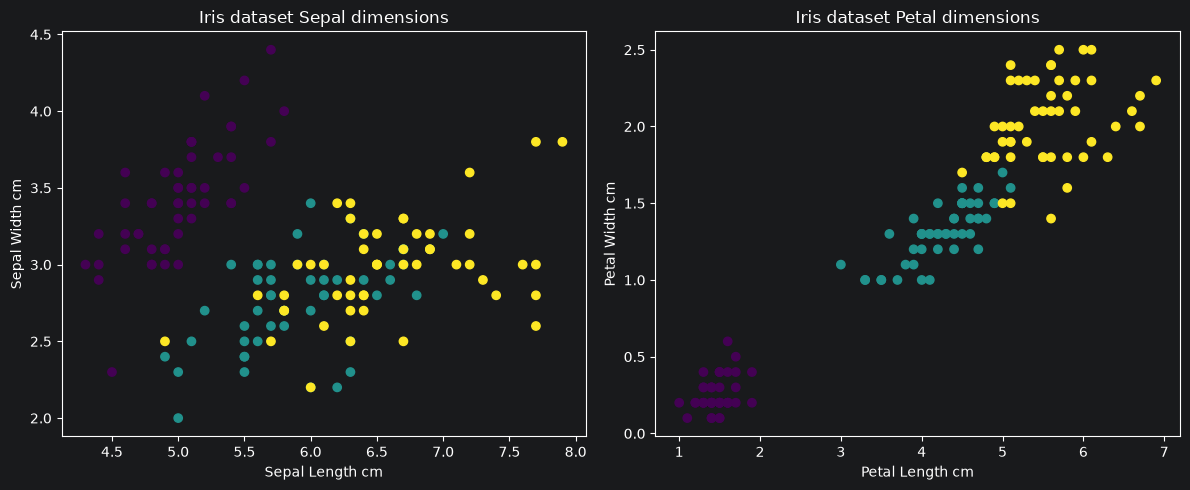

In [31]:
figure, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(iris_df.iloc[:, 0], iris_df.iloc[:, 1], c=iris.target)
axes[0].set_xlabel('Sepal Length cm')
axes[0].set_ylabel('Sepal Width cm')
axes[0].set_title('Iris dataset Sepal dimensions')

axes[1].scatter(iris_df.iloc[:, 2], iris_df.iloc[:, 3], c=iris.target)
axes[1].set_xlabel('Petal Length cm')
axes[1].set_ylabel('Petal Width cm')
axes[1].set_title('Iris dataset Petal dimensions')

plt.tight_layout()
plt.show()

The visualisation shows that the three Iris genera are distributed differently within the trait space. **Setosa** (dark purple/blue) forms a relatively distinct group, whilst **Versicolour** (green) and **Virginica** (yellow) overlap to some extent. The two traits shown therefore already allow for a certain degree of distinction between the classes, but are not sufficient to clearly distinguish all the flowers from one another.


## Creating Sets

The next step is to prepare the dataset so that independent variables or references can be used for the **features** and **target classes**. Subsequently, the subsets required for the **model training and testing** steps – which must be carried out independently of one another – must be formed from this. This allows model training and the subsequent evaluation of the model to be carried out on separate data sets.

The features are usually stored in a variable labelled X, whilst the corresponding target classes are stored in a variable labelled y. These variables are arrays (NumPy arrays).

In multidimensional arrays or matrices, the individual elements are addressed via a row index and a column index. Typically, a row represents a single sample, whilst the columns contain the corresponding features.

These arrays (NumPy arrays) are implemented as objects from the NumPy library. 

Documentation: https://numpy.org/doc/stable/user/index.html#user

In our Iris dataset, the features of the samples are therefore stored as values in a row of the variable X (one sample per row), whilst the target classes are stored as values of the variable y. The lengths and widths of the sepals (sepal length and width) and the lengths and widths of the petals (petal length and width) of a measured iris flower are therefore stored in a row of the feature matrix X.
The individual samples are therefore read via the row index, whilst their features are read via the column index.

The genera of the various irises (**Setosa**, **Versicolour**, **Virginica**) are numerically encoded using integers (**Setosa** 0, **Versicolour** 1, **Virginica** 2) and stored as target classes in the variable y for each sample.

### ***Task 3***
In the programme cell below, references to the dataset are to be created in the variables *X* and *y*. *X* must be defined as a reference (view) to the first two attributes of the Iris dataset, namely the **lengths and widths of the sepals (Sepal Length and Sepal Width)**, and *y* as a reference to the target classes of the Iris dataset.


In [ ]:
# Task 3
X = iris.data[:, :2]
y = iris.target

### Creating a training and test set

For model training, the dataset is split into **training and test data**. The training data is used to learn or store the information required for the respective method. The test data is not taken into account during this process and is only used afterwards to evaluate the model’s performance. This allows us to check how well the model generalises to previously unknown data.

The distinction between training and test data is important for assessing the model’s ability to generalise.
To this end, the next step involves splitting both the stored features and their target classes from the dataset into subsets for training *(X_train, y_train)* and testing *(X_test, y_test)*.

As no separate validation dataset is used in this case, 80 per cent of the data is typically used for training and 20 per cent for the final testing. Using the training data, the two models to be compared learn the patterns contained in the data and determine their model parameters. The test data is not taken into account during training and is only used afterwards to independently evaluate the model’s performance on previously unknown data.

To split the dataset, we use the **train_test_split** function from the **Scikit-Learn library**.

### **Task 4**

Next, import the **train_test_split** function from the relevant **Scikit-Learn** module into the **first programme cell you have already created**.

This function will be used later to split the dataset into **training and test data**.

Documentation: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

### **Task 5**

In the following programme cell, create 4 variables for the separate training and test data sets from the features in the variable *X* and the target labels in the variable *y* with the following names:

1.   X_train
2.   X_test
3.   y_train
4.   y_test

The variables should be created and populated using the *train_test_split* function. 

Documentation: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

To ensure that the random selection of samples is **reproducible** when the function is called repeatedly, the variable **random_state** must be set to a specific integer value when the function is called.

The proportion of the test data set should be 20% (0.2). 

To ensure that the ratio of classes in the training and test data sets roughly corresponds to the ratio in the overall dataset, the variable **stratify=y** is set.

In [ ]:
# Task 5
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)

# Part B: K-Nearest Neighbour Classification
Part B instantiates, trains and evaluates the K-Nearest Neighbour (k-nearest-neighbour) classification algorithm

## Create an instance of the K-nearest-neighbour classification

The K-nearest neighbours (KNN) algorithm is a non-parametric classification method. For a new, unknown sample, the algorithm considers the k training samples that are most similar to this sample in the feature space. Similarity is usually determined using a distance metric, such as Euclidean distance. The class of the new sample is then determined by a majority decision based on the k nearest neighbours.
The key difference from a parametric model is that KNN does not learn any model parameters, such as weights. Instead, the training data is stored and used during classification. The hyperparameter k determines how many neighbours are taken into account for the classification decision.

Documentation https://de.wikipedia.org/wiki/N%C3%A4chste-Nachbarn-Klassifikation

### **Task 6**
KNN classification is already implemented in the https://scikit-learn.org/ library. To use the *KNeighboursClassifier* class, it must first be imported in the first code cell.

Documentation: https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html


### **Task 7**
Both the description and the metadata indicate that the dataset describes three genera of iris. Each genus of the respective iris flower is numerically encoded by a unique integer: **Setosa** is represented by (0), **Versicolour** by (1) and **Virginica** by (2). These coded target classes are stored as values of the field variable *y* (NumPy array) for each sample.

It follows that the classification model must be able to distinguish between or recognise three different classes. This is therefore a multi-class classification problem with three classes.
 
In the following code block, an instance of K-nearest-neighbour classification is to be created. The number of neighbours to be considered must be set to *k=5* (n_neighbours). The parameter *k* (n_neighbours) determines how many of the nearest training samples are used for the classification decision. The *k* neighbours are the *k* training samples that lie closest to a new, unknown sample in the feature space.

In simple terms, the classification process works as follows:

1) A new sample is passed to the KNN model.
2) The model calculates the distance between this sample and all the training samples.
3) The *k* nearest samples are selected.
4) The classes of these neighbours are considered.
5) The class with the most votes is used as the prediction for the new sample.

Example: When *k=5*, three of the five nearest neighbours belong to the **Setosa** class, one to **Versicolour** and one to **Virginica**. The new sample is therefore classified as **Setosa** (class 0).

In [ ]:
# Task 7
knn = KNeighborsClassifier(n_neighbors=5)

## Model Training
Once an instance of the K-nearest-neighbour classifier has been created, the model can be trained.

Unlike parametric models, no model parameters such as weights are learnt during the training of the K-nearest-neighbour classifier. Instead, the training data are stored along with their corresponding target classes. The actual classification decision is only made during the subsequent prediction: for an unknown sample, the *k* nearest training samples are identified and their classes are used for the prediction, as described above.

### **Task 8**

Model training is to be implemented in the programme cell below. To do this, use the created instance of the KNN classifier *knn* and call its *.fit()* method. Both the features and the target labels of the training samples *X_train* and *y_train* are passed as parameters to the *.fit()* method.

The features of the samples used to train the model are already stored in the variable *X_train*. The corresponding target labels are stored in the variable *y_train*.
    
Documentation (*.fit()*): https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html#sklearn.neighbors.KNeighborsClassifier.fit

In [ ]:
# Task 8
knn.fit(X_train, y_train)

## Checking accuracy

Once the model has been trained, we can use it to classify the samples from the test dataset as Iris **Setosa**, Iris **Versicolour** or Iris **Virginica**, based on their features. By comparing the class predicted by the model with the reference class from the test set, we can determine the model’s accuracy.

To do this, the features of the samples from the test set must first be classified using the **.predict()** method. .....



### **Task 9**

To test the accuracy and then visualise the results, we need to import two final methods: *confusion_matrix* and *accuracy_score* from the *metrics* module of the Scikit-Learn library.

Try to work out for yourself, using the documentation, how to import these.

Documentation (*metrics*): https://scikit-learn.org/stable/modules/classes.html#module-sklearn.metrics

Documentation (*confusion_matrix*): https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html

Documentation (*accuracy_score*): https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html



### **Task 10**

In the programme block below, you are to implement the classification of the samples from the test dataset using the *.predict()* method of the *knn* instance. To do this, only the features of the samples from the test dataset should be passed to the variable *X_test*.

The *.predict()* method should store the result in a variable *y_pred*.

Documentation (*.predict()*): https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html#sklearn.neighbors.KNeighborsClassifier.predict

In [ ]:
# Task 10
y_pred = knn.predict(X_test)

### **Task 11**

In the following programme cell, determine and output the accuracy using the *accuracy_score* method, based on the classification result stored in the variable *y_pred* and the class labels of the samples from the test dataset *y_test*.

Documentation: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html

In [ ]:
# Task 11
accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {accuracy:.1%}")

### **Task 12**
In the following programme cell, the **confusion matrix** is used to determine how well the classes predicted by the model correspond to the actual classes in the test dataset. It compares the actual target classes with the classes predicted by the model. This allows us to see how many samples were correctly classified in each case and which classes were confused with one another. The correctly classified samples are located on the **main diagonal** of the matrix, whilst the entries outside the diagonal represent **misclassifications**.

To do this, use the *confusion_matrix()* function, which instantiates the confusion matrix as an array (NumPy array). 

Documentation: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html


We store the result in a variable *cm*.

In [ ]:
# Task 12
cm = confusion_matrix(y_test, y_pred)
print(cm)

## Visualisation and analysis of model behaviour
As the KNN model was trained using only the two features **Sepal Length** and **Sepal Width**, its decision boundaries can be plotted in a two-dimensional coordinate system. To do this, a fine grid is first superimposed over the range of values for the two features. For each point on this grid, the KNN model determines the predicted Iris genus. The predicted classes are then colour-coded. The transitions between the coloured regions show the **decision boundaries of the KNN model**.


In [ ]:
h = .02
cmap_light = ListedColormap(['#3D0752', '#4D8E8C', '#F7E846'])
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))
Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)
plt.figure()
plt.pcolormesh(xx, yy, Z, cmap=cmap_light)

### **Task 13** 
In the first experiment, the KNN model was trained using only two features: **Sepal Length** and **Sepal Width**. The two features relating to the petals (**Petal Length** and **Petal Width**) were not taken into account.

In the following code block, the features of the samples must now be expanded to include the two additional features, so that all four available features can be used for training and classification. 
To do this, the reference to the array containing all the features of the Iris dataset must now be stored in the variable *X*, the features in the variable *X* and the target labels in the variable *y* must be split again into training and test data, and the KNN model must be trained using the 4 features via the *.fit()* method. The classes of the test samples are then classified using the *.predict()* method. Finally, both the model’s accuracy on the test dataset and the confusion matrix must be recalculated and displayed.

In [ ]:
# Task 13
X = iris.data

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f"Four-feature KNN accuracy: {accuracy:.1%}")
print(cm)

### **Task 14** 
The Iris dataset is a very simple and straightforward dataset. It is based on just four meaningful features, the measurements of which were collected under relatively controlled conditions and are therefore only minimally affected by measurement errors or technical interference. Real-world datasets, on the other hand, often contain measurement uncertainties, sources of interference and additional features that are of little or no relevance to classification. To simulate these more realistic conditions, interference and additional noise features will be deliberately added to the dataset below.

In the following code block, a copy *X_noisy* of the original features *X* is first created for this purpose. Next, a randomly generated value from a normal distribution with a mean of 0 and a standard deviation of 0.8 is to be added to each feature value of the variable *X_noisy*. This ensures that the features of all samples – and thus all three Iris classes – are affected equally by noise.

Documentation https://numpy.org/doc/stable/reference/random/generated/numpy.random.normal.html

The parameters should be set as follows:

Mean: 0 – no systematic shift

Standard deviation: 0.8 – strength of the noise

Shape: exactly as many random values as there are features

The noisied dataset is then split into training and test data, as previously done.

The KNN model is trained exclusively on the noisied training data. The test data, which is also noisied, is then classified. The classification performance should be evaluated using the *accuracy_score* method. In addition, the confusion matrix should be generated and output using the *confusion_matrix* method to examine how frequently the individual Iris classes were classified correctly or incorrectly.


In [ ]:
# Task 14
X_noisy = X.copy()
rng = np.random.default_rng(42)
X_noisy += rng.normal(loc=0, scale=0.8, size=X_noisy.shape)

X_noisy_train, X_noisy_test, y_noisy_train, y_noisy_test = train_test_split(
    X_noisy, y, test_size=0.2, random_state=42, stratify=y
)

knn_noisy = KNeighborsClassifier(n_neighbors=5)
knn_noisy.fit(X_noisy_train, y_noisy_train)
y_noisy_pred = knn_noisy.predict(X_noisy_test)

noisy_accuracy = accuracy_score(y_noisy_test, y_noisy_pred)
print(f"Noisy KNN accuracy: {noisy_accuracy:.1%}")
print(confusion_matrix(y_noisy_test, y_noisy_pred))

## Experimenting
To experiment, the algorithm’s **k-value** can be altered. It is interesting to see how different *k*-values affect the model’s **decision thresholds** and **accuracy**.

# Part C: Multi-layer perceptron
Part C instantiates, trains and evaluates the classification of iris genera based on a multi-layer perceptron.

The multi-layer perceptron (MLP) is a parametric artificial neural network consisting of several interconnected layers of neurons. For this classification task, the four features of an iris flower are used as input. The input layer therefore has four input values.

The input layer is followed by one or more hidden layers. The neurons in these layers compute weighted sums of the input values or the outputs of the preceding layer and apply an activation function to them. Thanks to the multiple layers, the MLP can learn more complex relationships between the features and the target classes.

The output layer consists of three output neurons, as the dataset distinguishes between three species of iris. Each output neuron represents one of the classes **Setosa**, **Versicolour** and **Virginica**. The class with the highest output is used as the model’s prediction.

Unlike the K-nearest neighbours algorithm, the MLP learns model parameters during training. These include, in particular, the weights and bias values of the connections between the neurons. These parameters are adjusted step by step using the training data so that the model’s predictions match the specified target classes as closely as possible.

Documentation https://scikit-learn.org/stable/modules/neural_networks_supervised.html

Before training the MLP, the features must be standardised using the **StandardScaler**. In this process, each feature is transformed independently of the others so that it has a mean of 0 and a standard deviation of 1. This ensures that the four features are on a comparable scale. This can contribute to more stable and efficient training, particularly when optimising the weights of a neural network.

Only the **training data** is used to calculate the scaling parameters. The means and standard deviations determined in this way are then applied unchanged to the **test data**. This prevents information from the test dataset from being incorporated into the training.


### **Task 15**
The *StandardScaler* is already implemented in the https://scikit-learn.org/ library. To use the *StandardScaler* class, it must first be imported in the first programme code cell.

Documentation https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler

### **Task 16**
To apply the *StandardScaler*, you must first instantiate it. The mean and standard deviation of each feature are then determined from the **training data** using the *.fit()* method. These values are used to standardise the training data using the *.transform()* method. Alternatively, the compact version *.fit_transform()* can also be used for the **training data**. The scaling parameters determined are then also used to transform the test data using the *.transform()* method.

It should be noted at this point that the *.fit()* method of the *StandardScaler* is applied after the dataset has been split into training and test data, and using the features stored in the variable X.

https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler documentation


In [ ]:
# Task 16
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### **Task 17**
To solve the classification task using a multilayer perceptron (MLP) defined with Keras:

The MLP is structured as a *sequential* model, in which the layers are arranged one after the other. The first and second layers are both fully connected (`Dense`) layers with **10 neurons** and use the **ReLU activation function**. These two hidden layers enable the model to learn non-linear relationships between the four iris features.

The final layer has **three neurons**, as the model must distinguish between the three iris genera **Setosa**, **Versicolour** and **Virginica**. The **Softmax** activation function is used. This means that the three outputs are interpreted as probabilities for the respective class. The sum of the three output values is 1. The class with the highest probability is selected as the predicted class.

The MLP thus consists of an input layer with four features, two hidden layers, each with ten neurons, and an output layer with three neurons.

The Keras API is used for implementation. To do this, the relevant packages must be imported from the library in the first programme cell.

Documentation https://www.tensorflow.org/guide/keras/sequential_model

Furthermore, after importing the Keras API, the random number generator must be set to a defined initial state using *keras.utils.set_random_seed(42)*. This ensures that the random processes used are reproducible when the programme is run repeatedly under the same conditions.

### **Task 18**
The number of neurons in the hidden layers is not determined by the number of classes, but is instead a hyperparameter of the MLP. For the first trial, two hidden layers, each with 10 neurons, are used. The output layer, however, has exactly three neurons due to the three iris species to be distinguished.

The **ReLU activation function (rectified linear unit)** is used in the hidden layers of the MLP because it enables the neural network to model non-linear relationships between the features.

Instantiate the MLP using the **Sequential** class from the Keras package. The individual layers of the neural network are listed in order. Define the model consisting of 2 hidden layers, each with 10 neurons and the ReLU activation function, and an output layer with 3 neurons and the Softmax activation function.

In [ ]:
# Task 18
mlp = keras.Sequential([
    keras.Input(shape=(4,)),
    keras.layers.Dense(10, activation="relu"),
    keras.layers.Dense(10, activation="relu"),
    keras.layers.Dense(3, activation="softmax"),
])

mlp.summary()

### **Task 19**
Once the individual layers of the MLP have been defined, the model must be configured for training in the following programme cell using the **.compile()** method. In particular, the loss function and the optimisation algorithm must be specified. The loss function determines the magnitude of the prediction error, whilst the optimisation algorithm specifies how the trainable model parameters are adjusted to reduce this error. In addition, **accuracy** is used to define a metric by which the classification performance can be monitored during training.
 
https://keras.io/api/models/model_training_apis/ documentation

**sparse_categorical_crossentropy** is used as the loss function. This loss function is suitable for multi-class classification tasks where the target classes are represented as integer values. This corresponds to the encoding of our Iris dataset, in which **Setosa**, **Versicolour** and **Virginica** are represented by the values 0, 1 and 2, in contrast to one-hot vector encoding, where the values **Setosa**, **Versicolour**, **Virginica** are represented as [1, 0, 0], [0, 1, 0] and [0, 0, 1]. The loss function evaluates how well the class probabilities predicted by the MLP match the actual target class. A high error occurs in particular when the model assigns a low probability to the class that is actually correct.

Adam (Adaptive Moment Estimation) is used as the optimisation algorithm. Adam gradually adjusts the trainable model parameters of the MLP, in particular the weights and bias values, during training. This is based on the gradients of the loss function calculated via backpropagation. Adam takes into account both the current gradient and its historical development, and uses this to determine adaptive update steps for the individual parameters. This allows the optimisation process to be efficiently adapted to the different parameters of the neural network.

Documentation: https://keras.io/api/optimizers/adam/

**Accuracy** is used as a metric to evaluate classification performance. It describes the proportion of correctly classified samples out of the total number of samples considered. An accuracy of 1 or 100 per cent means that all samples have been correctly classified, whilst an accuracy of 0.5 means that half of the samples have been correctly classified.

**Accuracy** is a suitable metric for the Iris dataset in question, as the three target classes occur with approximately equal frequency. Consequently, the overall accuracy is not significantly influenced by a single, over-represented class.

Documentation https://keras.io/api/metrics/

In [ ]:
# Task 19
mlp.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

### **Task 20**
Once the MLP has been successfully configured, the model parameters must be trained using the **.fit()** method. In doing so, the features are passed via the variable X_train and the corresponding target classes via the variable y_train from the scaled training data. Training should be carried out over 100 epochs. One epoch corresponds to one complete pass through the training dataset. The training samples are processed in batches of 8, so that the model parameters are updated after every eight training samples. During training, the MLP’s parameters are gradually adjusted using backpropagation and the Adam optimiser to minimise the **loss function**.

https://keras.io/api/models/model_training_apis/ documentation

Control the output of information during training using the **verbose=1** parameter of the **.fit()** method. For each epoch, a progress bar is displayed showing the current training metrics, such as the **loss function** and **accuracy**.



In [ ]:
# Task 20
history = mlp.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=8,
    verbose=1,
)

The model parameters are not automatically trained successfully after a specific number of epochs. Training is considered successful if the model demonstrates good generalisation performance on data not used for training; that is, if it not only processes the specific training data correctly, but can also transfer the relationships learnt from it to new, unknown data.
During training, the weights and bias values are adjusted incrementally. The **loss** should generally decrease. The **accuracy** on the training data should improve. However, what is crucial is the performance on the test dataset (or a validation dataset, if available). We simplify this approach in this exercise.

### **Task 21**
Once the model parameters have been trained, the model must be evaluated using the test data. To do this, predictions are first generated for all samples in the test dataset using **mlp.predict(X_test)**. The MLP returns three output values for each sample, which, due to the softmax activation function used, can be interpreted as probabilities for the three Iris classes.

Documentationhttps://keras.io/api/models/model_training_apis/

**np.argmax(y_pred, axis=1)** is then used to select the class with the highest probability for each sample. This yields the predicted classes **y_pred_classes**, which can be compared with the actual target classes **y_test**.

Documentation https://numpy.org/doc/stable/reference/generated/numpy.argmax.html

The **accuracy_score()** function calculates the model’s accuracy on the test dataset based on the actual and predicted classes. It therefore indicates the proportion of test samples that were correctly classified.

Documentation https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html#sklearn.metrics.accuracy_score

A confusion matrix is then generated using **confusion_matrix()**. It compares the actual classes with the classes to which the model has assigned the test samples. This allows us to identify not only the overall accuracy but also which Iris genera the model may have difficulty distinguishing between.

Documentation https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html

As in the example above, the same methods are used to evaluate the predictions.

In [ ]:
# Task 21
y_pred = mlp.predict(X_test_scaled, verbose=0)
y_pred_classes = np.argmax(y_pred, axis=1)

accuracy = accuracy_score(y_test, y_pred_classes)
cm = confusion_matrix(y_test, y_pred_classes)

print(f"Clean MLP test accuracy: {accuracy:.1%}")
print(cm)

### **Task 22**
In the cell below, the training and testing should be repeated using the dataset modified by disturbances and additional noise features.
To avoid differences between the noisy datasets, the **features already made noisy for the K-nearest-neighbour experiment** (X_noisy_train, X_noisy_test) should be used for the MLP. This ensures that both models are trained and tested under identical data conditions, so that the results obtained can be directly compared with one another.


In [ ]:
# Task 22
noisy_scaler = StandardScaler()
X_noisy_train_scaled = noisy_scaler.fit_transform(X_noisy_train)
X_noisy_test_scaled = noisy_scaler.transform(X_noisy_test)

keras.utils.set_random_seed(42)
mlp_noisy = keras.models.clone_model(mlp)
mlp_noisy.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

mlp_noisy.fit(
    X_noisy_train_scaled,
    y_noisy_train,
    epochs=100,
    batch_size=8,
    verbose=1,
)

noisy_probabilities = mlp_noisy.predict(X_noisy_test_scaled, verbose=0)
noisy_classes = np.argmax(noisy_probabilities, axis=1)

noisy_mlp_accuracy = accuracy_score(y_noisy_test, noisy_classes)
print(f"Noisy MLP test accuracy: {noisy_mlp_accuracy:.1%}")
print(confusion_matrix(y_noisy_test, noisy_classes))


### **Task 23**
The findings from the evaluation of the various models are summarised here. The focus is on the influence of the number of features used, the type of model (KNN versus MLP) and the effect that adding noise with different standard deviations has on the overall result. To vary the influence of the noise, the standard deviation in Task 13 can be set to different values, for example between 0.1 and 0.9.

As the noise is generated randomly, the classification accuracy of the two models may vary from one run to the next. Depending on the noise pattern generated, the MLP may achieve higher accuracy on one occasion, whilst the K-nearest-neighbour method may do so on another. A single trial therefore does not allow for a general conclusion as to which model is more robust to noise.

To enable a more meaningful comparison, the experiment can be carried out multiple times with different noise patterns, and subsequently, for example, the **average accuracy** of the two models can be compared.
